# 04 — Outliers: Diamonds

Ciência de Dados — Atividade 05: Revisão

Autor: Carlos Gabriel Raposo Landim

Base real: [seaborn-data — diamonds.csv](https://github.com/mwaskom/seaborn-data/blob/master/diamonds.csv)

Os arquivos originais estão em `dados/`. As células foram executadas na ordem apresentada. Cada estratégia usa uma cópia; resultados experimentais não são evidência de qualidade preditiva. Em modelos, separar treino/teste antes de ajustar imputadores e escalonadores.

## Importações e carregamento dos dados

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
DADOS = Path('dados')
RESULTADOS = Path('resultados')
RESULTADOS.mkdir(exist_ok=True)
import seaborn as sns
# Cópia do mesmo CSV usado por sns.load_dataset('diamonds'), para execução offline.
df = pd.read_csv(DADOS/'diamonds/diamonds.csv')
original = df.copy(deep=True)
numericas = df.select_dtypes(include='number').columns.tolist()
print('Dimensões:', df.shape)
display(df[numericas].describe().T)
impossiveis = (df[['x','y','z']]<=0).any(axis=1)
print('Linhas com dimensão física não positiva:', impossiveis.sum())
display(df.loc[impossiveis,['carat','price','x','y','z']])

Dimensões: (53940, 10)
Linhas com dimensão física não positiva: 20


,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


,carat,price,x,y,z
2207,1.00,3142,6.55,6.48,0.0
2314,1.01,3167,6.66,6.60,0.0
4791,1.10,3696,6.50,6.47,0.0
5471,1.01,3837,6.50,6.47,0.0
10167,1.50,4731,7.15,7.04,0.0
11182,1.07,4954,0.00,6.62,0.0
11963,1.00,5139,0.00,0.00,0.0
13601,1.15,5564,6.88,6.83,0.0
15951,1.14,6381,0.00,0.00,0.0
24394,2.18,12631,8.49,8.45,0.0


x, y e z representam comprimento, largura e profundidade em milímetros. Zero não descreve um diamante físico; é registro inválido ou ausência codificada, sem informação suficiente para recuperar a medida. Valores muito altos e proporções estranhas são suspeitos, mas exigem confirmação da fonte.

## Detecção — Z-score e IQR

,z_maior_3,fora_1_5_IQR,intersecao,limite_inferior,limite_superior
carat,439,1889,439,-0.560,2.000
depth,685,2545,685,58.750,64.750
table,336,605,336,51.500,63.500
price,1206,3540,1206,-5611.375,11885.625
x,43,32,32,1.965,9.285
y,34,29,29,1.990,9.270
z,55,49,49,1.215,5.735


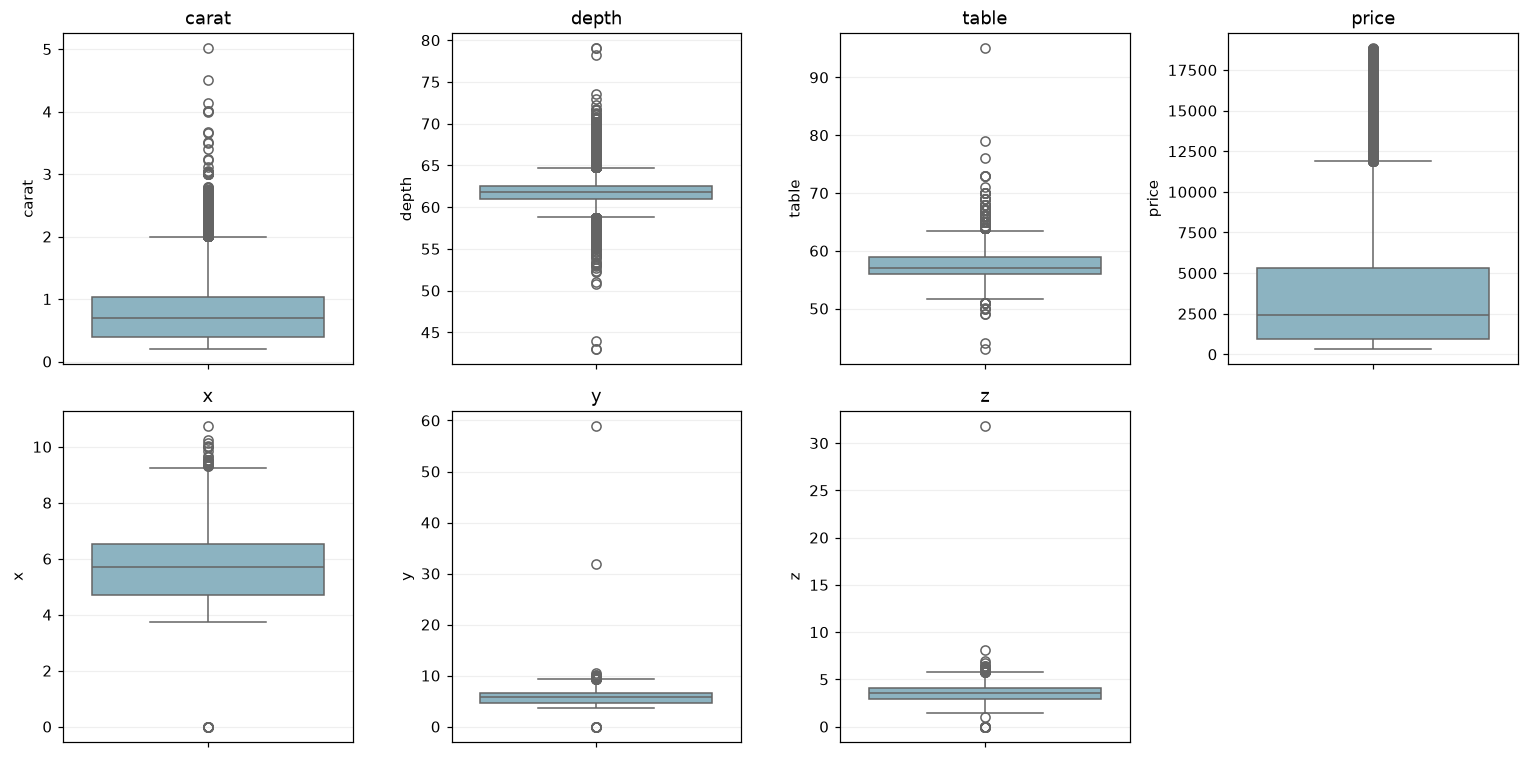

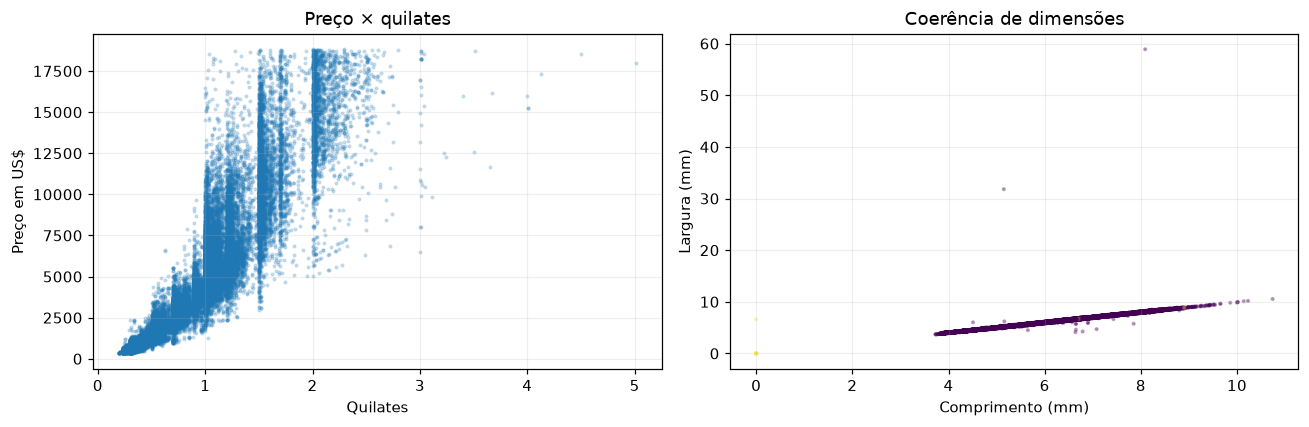

In [2]:
zscore = (df[numericas]-df[numericas].mean())/df[numericas].std(ddof=0)
q1,q3 = df[numericas].quantile(.25),df[numericas].quantile(.75)
iqr = q3-q1
inferior,superior = q1-1.5*iqr,q3+1.5*iqr
flag_z = zscore.abs()>3
flag_iqr = df[numericas].lt(inferior)|df[numericas].gt(superior)
display(pd.DataFrame({'z_maior_3':flag_z.sum(),'fora_1_5_IQR':flag_iqr.sum(),'intersecao':(flag_z&flag_iqr).sum(),'limite_inferior':inferior,'limite_superior':superior}).round(3))
fig,axs=plt.subplots(2,4,figsize=(14,7))
for ax,col in zip(axs.flat,numericas):
    sns.boxplot(y=df[col],ax=ax,color='#83b7ca'); ax.set_title(col)
axs.flat[-1].axis('off'); plt.tight_layout(); plt.show()
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].scatter(df.carat,df.price,s=3,alpha=.2)
axs[0].set(xlabel='Quilates',ylabel='Preço em US$',title='Preço × quilates')
axs[1].scatter(df.x,df.y,c=impossiveis.astype(int),s=3,alpha=.3)
axs[1].set(xlabel='Comprimento (mm)',ylabel='Largura (mm)',title='Coerência de dimensões')
plt.tight_layout(); plt.show()

## Erro × valor extremo legítimo
Dimensões não positivas são inválidas para análise física. As dimensões extremas devem ser auditadas. Quilates e preço elevados são candidatos a casos raros legítimos: um critério univariado não comprova erro. Não afirmo que todo ponto acima do limite seja falso nem que todo valor positivo seja correto.

## Tratamento — Remoção, capping e transformação
Retiro as dimensões não positivas de uma base de comparação física. A partir dela, comparo três alternativas para price: remover preços fora do IQR, limitar price aos limites IQR, e aplicar log1p. As duas primeiras são experimentos de sensibilidade, não uma recomendação para apagar diamantes caros. A transformação muda a unidade, por isso apresento também o retorno à escala original.

Preços alterados pelo capping: 3532
Diamantes > 4 quilates: 5


,count,mean,std,min,25%,50%,75%,max,assimetria
Original,53940.0,3932.800,3989.440,326.00,950.000,2401.000,5324.25,18823.000,1.618
Sem dimensões inválidas,53920.0,3930.993,3987.280,326.00,949.000,2401.000,5323.25,18823.000,1.618
Remoção IQR,50388.0,3159.275,2764.925,326.00,911.000,2154.000,4668.25,11883.000,1.189
Capping IQR,53920.0,3730.825,3435.755,326.00,949.000,2401.000,5323.25,11884.625,1.149
Log1p (outra unidade),53920.0,7.787,1.014,5.79,6.856,7.784,8.58,9.843,0.116
Log invertido,53920.0,3930.993,3987.280,326.00,949.000,2401.000,5323.25,18823.000,1.618


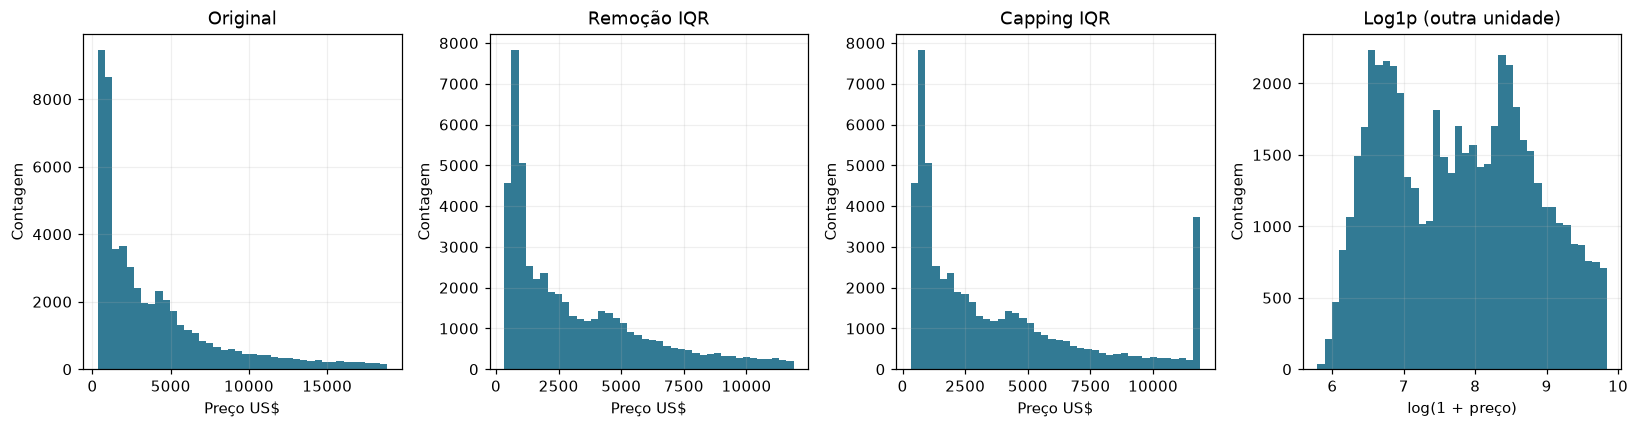

In [3]:
base = df.loc[~impossiveis].copy()
p1,p3 = base.price.quantile([.25,.75]); piqr=p3-p1
lo,hi=p1-1.5*piqr,p3+1.5*piqr
remocao=base.loc[base.price.between(lo,hi)].copy()
capping=base.copy(); capping['price']=capping.price.clip(lower=lo,upper=hi)
transformacao=base.copy(); transformacao['log_price']=np.log1p(transformacao.price)
series={'Original':df.price,'Sem dimensões inválidas':base.price,'Remoção IQR':remocao.price,'Capping IQR':capping.price,'Log1p (outra unidade)':transformacao.log_price,'Log invertido':np.expm1(transformacao.log_price)}
comparacao=pd.DataFrame({nome:s.describe() for nome,s in series.items()}).T
comparacao['assimetria']=pd.Series({nome:s.skew() for nome,s in series.items()})
display(comparacao.round(3))
print('Preços alterados pelo capping:',base.price.ne(capping.price).sum())
print('Diamantes > 4 quilates:',df.carat.gt(4).sum())
fig,axs=plt.subplots(1,4,figsize=(15,4))
for ax,nome in zip(axs,['Original','Remoção IQR','Capping IQR','Log1p (outra unidade)']):
    ax.hist(series[nome],bins=40,color='#327a94'); ax.set(title=nome,xlabel='Preço US$' if 'Log' not in nome else 'log(1 + preço)',ylabel='Contagem')
plt.tight_layout(); plt.show()
assert df.equals(original)
assert np.allclose(np.expm1(transformacao.log_price),base.price)
comparacao.to_csv(RESULTADOS/'04_comparacao.csv')

## Respostas às perguntas de reflexão
1. O cálculo de Z-score existe para distribuições com média e desvio finitos, mas interpretar ±3 como evento excepcional pressupõe uma distribuição aproximadamente normal. O histograma de price mostra assimetria à direita e não uma curva simétrica; o IQR também é uma regra de triagem, não um diagnóstico de erro.
2. Mais de quatro quilates pode ser raridade real. Para estudar o mercado de luxo, preservar esses casos é essencial. Em um modelo do segmento popular, poderia delimitar explicitamente a população por faixa e justificar essa decisão de negócio, sem rotular valores altos como inválidos.
3. Na detecção de fraude, operações anormais podem ser justamente o alvo. Removê-las antes de investigar apagaria o sinal. Isso também acontece ao estudar artigos de luxo ou falhas de sensores.
4. Remoção reduz a amostra e pode baixar a média; capping acumula valores no teto e altera preços reais; log preserva a ordem e comprime a cauda, mas exige interpretar a escala. Escolheria preservar o preço original e criar log_price, além de auditar as medidas físicas suspeitas.

Referência das unidades: [ggplot2 — diamonds](https://ggplot2.tidyverse.org/reference/diamonds.html).

## Síntese dos resultados executados

Foram encontrados 20 registros com dimensões não positivas. Após excluí-los para a comparação física, a remoção por IQR de price reteve 50,388 linhas e o capping alterou 3,532 preços. A assimetria passou de 1.618 para 0.116 com log1p; isso melhora a simetria, mas não prova normalidade.